# Đề tài 3: Phân loại tin nhắn rác (SMS Spam Collection)
**Học phần Nhập môn Học máy (FIT4013) – Đại học Đại Nam**  |  Nhóm: *[điền số nhóm, thành viên]*

Notebook này đi qua toàn bộ quy trình: **EDA → chia dữ liệu → baseline → so sánh tiền xử lý/biểu diễn → tinh chỉnh tham số → đánh giá → phân tích lỗi → demo**.
Nó dùng lại các hàm trong `../src/common.py`, nên cho **cùng kết quả** với `python src/run_experiments.py`.

**Cách dùng:** chạy lần lượt từng ô (*Kernel → Restart & Run All*). Hai bước nặng có công tắc ở đầu notebook:
`RUN_STAGE1` (khoảng 1 phút) và `RUN_GRID` (khoảng 5–8 phút). Nếu để `False`, notebook đọc kết quả đã lưu trong `../results/`.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))      # để import common.py
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from common import (load_raw, normalize_text, make_pipeline, PREPROCESS, REPRESENT, RANDOM_STATE, ROOT)

# ----- công tắc cho các bước nặng -----
RUN_STAGE1 = True    # so sánh 36 cấu hình (tham số mặc định), ~1 phút
RUN_GRID   = False   # GridSearchCV theo từng ô, ~5-8 phút. False = đọc kết quả đã lưu

RES = ROOT / "results"
MODELS = ["MultinomialNB", "KNN", "DecisionTree"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

## 1. Khám phá dữ liệu (EDA)

In [2]:
raw = load_raw()
print("Số dòng:", raw.shape[0], "| thiếu:", int(raw.isna().sum().sum()))
print(raw["label"].value_counts().to_dict())
print("Số tin trùng lặp:", raw.duplicated("text").sum(),
      "| văn bản bị gán 2 nhãn:", int((raw.groupby("text").y.nunique() > 1).sum()))
raw.head()

Số dòng: 5574 | thiếu: 0
{'ham': 4827, 'spam': 747}
Số tin trùng lặp: 403 | văn bản bị gán 2 nhãn: 0


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


Có **403 tin trùng**. Nếu giữ lại, cùng một tin có thể rơi vào cả train lẫn test (rò rỉ dữ liệu), nên ta **bỏ trùng trước khi chia**.

Sau khi bỏ trùng: 5171 {'ham': 4518, 'spam': 653}
Tỉ lệ spam: 12.6%  -> bộ phân loại 'luôn đoán ham' đạt accuracy 87.4%


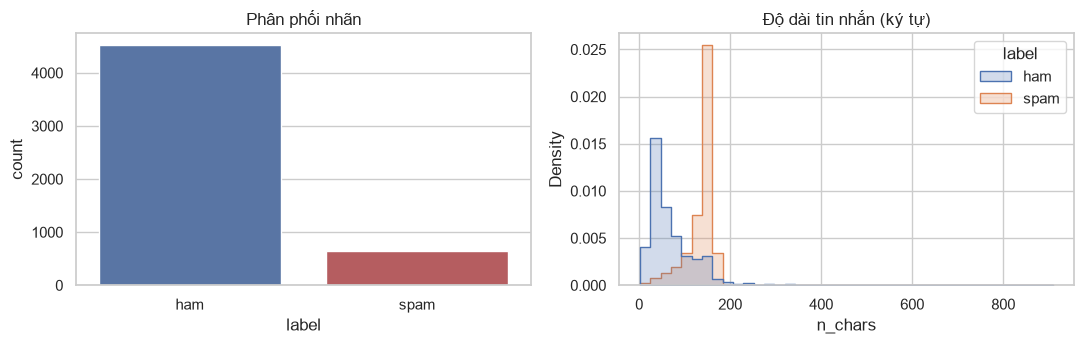

In [3]:
df = raw.drop_duplicates("text").reset_index(drop=True)
print("Sau khi bỏ trùng:", len(df), df["label"].value_counts().to_dict())
print(f"Tỉ lệ spam: {df.y.mean():.1%}  -> bộ phân loại 'luôn đoán ham' đạt accuracy {1-df.y.mean():.1%}")

df["n_chars"] = df.text.str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(data=df, x="label", ax=ax[0], palette=["#4C72B0", "#C44E52"]); ax[0].set_title("Phân phối nhãn")
sns.histplot(data=df, x="n_chars", hue="label", bins=40, stat="density", common_norm=False, element="step", ax=ax[1])
ax[1].set_title("Độ dài tin nhắn (ký tự)")
plt.tight_layout(); plt.show()

In [4]:
sig = pd.DataFrame({
    "chuỗi >=5 chữ số": df.text.str.contains(r"\d{5,}"),
    "URL/tên miền":     df.text.str.contains(r"www\.|http|\.com|\.co\.uk", case=False),
    "ký hiệu tiền tệ":  df.text.str.contains(r"[£$€]"),
    "độ dài (ký tự)":   df.n_chars,
}).groupby(df.label).mean().T
sig.round(3)

label,ham,spam
chuỗi >=5 chữ số,0.001,0.767
URL/tên miền,0.003,0.178
ký hiệu tiền tệ,0.004,0.332
độ dài (ký tự),70.895,137.711


**Nhận xét EDA:** spam dài hơn và tập trung; 76,7% spam chứa chuỗi số dài (số điện thoại/đầu số) so với 0,1% ở ham.
→ Giả thuyết: gom số dài/URL/tiền tệ về token chung (thay vì xoá) sẽ giúp mô hình.

## 2. Chia dữ liệu (train/test)

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(df["text"], df["y"], test_size=0.2,
                                          stratify=df["y"], random_state=RANDOM_STATE)
print("train:", len(X_tr), "(spam", int(y_tr.sum()), ") | test:", len(X_te), "(spam", int(y_te.sum()), ")")

train: 4136 (spam 522 ) | test: 1035 (spam 131 )


Từ đây, **mọi lựa chọn dùng CV 5-fold chỉ trên tập train**. Bộ vector hoá nằm *trong* `Pipeline` nên chỉ được fit trên phần train của từng fold (không rò rỉ dữ liệu).

## 3. Hàm đánh giá + Baseline

In [6]:
def get_score(pipe, X):
    clf = pipe.named_steps["clf"]
    return pipe.predict_proba(X)[:, 1] if hasattr(clf, "predict_proba") else pipe.decision_function(X)

def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), f1=f1_score(y, pred), roc_auc=roc_auc_score(y, get_score(pipe, X)))

# Baseline: BoW unigram, không tiền xử lý đặc biệt (P0), tham số mặc định
base_rows = {}
for m in MODELS:
    p = make_pipeline(m, "P0_raw", "BoW_uni").fit(X_tr, y_tr)
    base_rows[m] = evaluate(p, X_te, y_te)
baseline = pd.DataFrame(base_rows).T
baseline.round(4)

,accuracy,precision,recall,f1,roc_auc
MultinomialNB,0.9807,0.9512,0.8931,0.9213,0.9804
KNN,0.9082,1.0000,0.2748,0.4311,0.8130
DecisionTree,0.9691,0.9024,0.8473,0.8740,0.9170


K-NN baseline rất tệ vì khoảng cách Euclid trên vector đếm bị chi phối bởi độ dài tin nhắn (Bài 3: cần chuẩn hoá/chọn metric phù hợp).

## 4. Giai đoạn 1: so sánh tiền xử lý × biểu diễn (tham số mặc định)

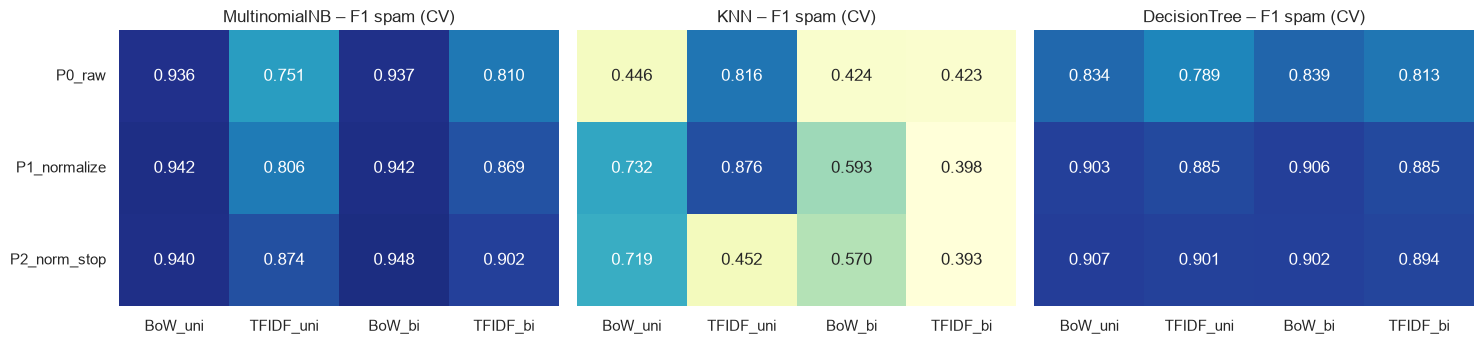

In [7]:
if RUN_STAGE1:
    rows = []
    for m in MODELS:
        for p in PREPROCESS:
            for r in REPRESENT:
                cv = cross_validate(make_pipeline(m, p, r), X_tr, y_tr, cv=CV, scoring="f1")
                rows.append(dict(model=m, prep=p, rep=r, cv_f1=cv["test_score"].mean()))
    s1 = pd.DataFrame(rows)
else:
    s1 = pd.read_csv(RES / "stage1_prep_repr_comparison.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, m in zip(axes, MODELS):
    piv = s1[s1.model == m].pivot(index="prep", columns="rep", values="cv_f1")[list(REPRESENT)].loc[list(PREPROCESS)]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.4, vmax=1, cbar=False, ax=ax)
    ax.set_title(f"{m} – F1 spam (CV)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Lưu ý phương pháp:** với tham số mặc định, TF-IDF + Naive Bayes (alpha=1) và K-NN (Euclid) bị đánh giá thấp *vì tham số chưa hợp*, chưa chắc vì bản thân biểu diễn.
Vì vậy bước tiếp theo **tinh chỉnh tham số cho từng ô** trước khi so sánh.

## 5. Giai đoạn 2: tinh chỉnh tham số (GridSearchCV, chỉ trên train)

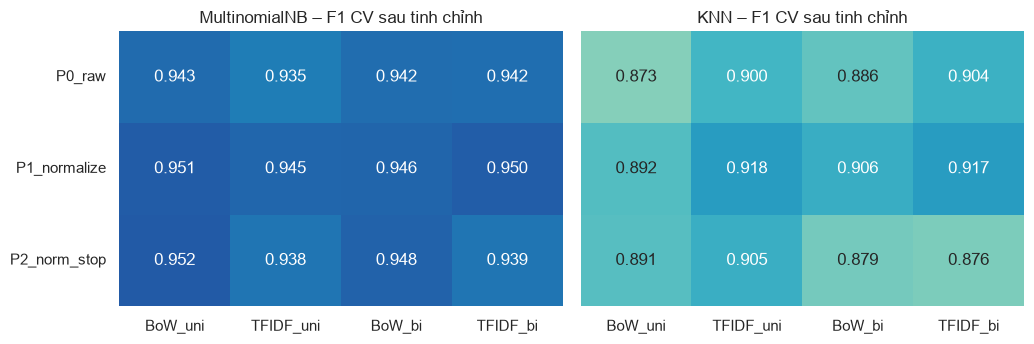

In [8]:
GRIDS = {
    "MultinomialNB": {"clf__alpha": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0], "clf__fit_prior": [True, False]},
    "KNN": {"clf__n_neighbors": [1, 3, 5, 7, 9, 15], "clf__metric": ["cosine", "euclidean"], "clf__weights": ["uniform", "distance"]},
    "DecisionTree": {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [None, 5, 10, 20, 40], "clf__min_samples_leaf": [1, 2, 5]},
}
if RUN_GRID:
    import tempfile
    from joblib import Memory
    MEM = Memory(tempfile.mkdtemp(), verbose=0)       # cache vector hoá theo fold (tăng tốc, không rò rỉ)
    rows = []
    for m in ["MultinomialNB", "KNN"]:
        for p in PREPROCESS:
            for r in REPRESENT:
                gs = GridSearchCV(make_pipeline(m, p, r, memory=MEM), GRIDS[m], scoring="f1", cv=CV).fit(X_tr, y_tr)
                rows.append(dict(model=m, prep=p, rep=r, tuned_cv_f1=gs.best_score_, **gs.best_params_))
    cells = pd.DataFrame(rows)
else:
    cells = pd.read_csv(RES / "stage2_tuned_per_cell.csv")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for ax, m in zip(axes, ["MultinomialNB", "KNN"]):
    piv = cells[cells.model == m].pivot(index="prep", columns="rep", values="tuned_cv_f1")[list(REPRESENT)].loc[list(PREPROCESS)]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.8, vmax=1, cbar=False, ax=ax)
    ax.set_title(f"{m} – F1 CV sau tinh chỉnh"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Khi mỗi ô được tinh chỉnh tham số, khoảng cách giữa các biểu diễn thu hẹp mạnh và TF-IDF không còn thua BoW một cách hệ thống.

## 6. Mô hình cuối cùng (cấu hình chọn theo CV)

In [9]:
BEST = {   # (tiền xử lý, biểu diễn, mô hình) – lấy từ results/summary.json
    "MultinomialNB": ("P2_norm_stop", "BoW_uni",   MultinomialNB(alpha=2.0, fit_prior=True)),
    "KNN":           ("P1_normalize", "TFIDF_uni", KNeighborsClassifier(n_neighbors=9, metric="cosine", weights="distance")),
    "DecisionTree":  ("P2_norm_stop", "BoW_uni",   DecisionTreeClassifier(criterion="gini", max_depth=10, min_samples_leaf=1, random_state=RANDOM_STATE)),
}
tuned = {m: make_pipeline(m, p, r, model=clf).fit(X_tr, y_tr) for m, (p, r, clf) in BEST.items()}
final = pd.DataFrame({m: evaluate(tuned[m], X_te, y_te) for m in MODELS}).T
final.round(4)

,accuracy,precision,recall,f1,roc_auc
MultinomialNB,0.9913,0.9766,0.9542,0.9653,0.9860
KNN,0.9826,0.9593,0.9008,0.9291,0.9918
DecisionTree,0.9874,1.0000,0.9008,0.9478,0.9500


In [10]:
cmp = pd.DataFrame({"F1 baseline": baseline.f1, "F1 tinh chỉnh": final.f1})
cmp["tăng"] = cmp["F1 tinh chỉnh"] - cmp["F1 baseline"]
cmp.round(4)

,F1 baseline,F1 tinh chỉnh,tăng
MultinomialNB,0.9213,0.9653,0.0440
KNN,0.4311,0.9291,0.4980
DecisionTree,0.8740,0.9478,0.0738


## 7. Đánh giá trên tập test

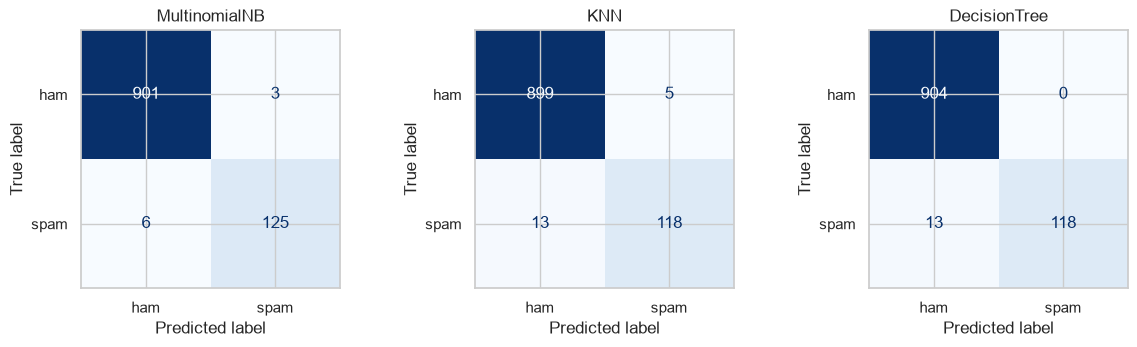

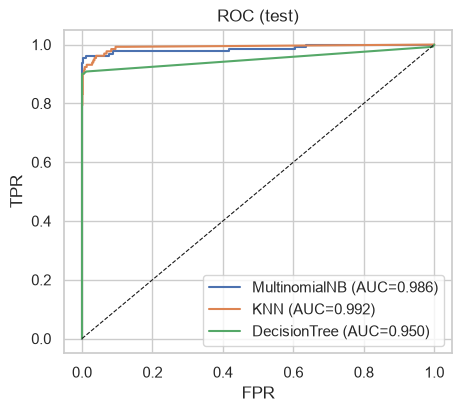

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, m in zip(axes, MODELS):
    ConfusionMatrixDisplay(confusion_matrix(y_te, tuned[m].predict(X_te)), display_labels=["ham", "spam"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(m)
plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 4.2))
for m in MODELS:
    s = get_score(tuned[m], X_te); fpr, tpr, _ = roc_curve(y_te, s)
    plt.plot(fpr, tpr, label=f"{m} (AUC={roc_auc_score(y_te, s):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=.8); plt.legend(loc="lower right"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (test)")
plt.show()

### Độ ổn định: lặp lại với 5 cách chia khác nhau (siêu tham số giữ cố định)

In [12]:
rows = []
for seed in range(5):
    Xa, Xb, ya, yb = train_test_split(df["text"], df["y"], test_size=0.2, stratify=df["y"], random_state=seed)
    for m in MODELS:
        rows.append(dict(seed=seed, model=m, **evaluate(clone(tuned[m]).fit(Xa, ya), Xb, yb)))
seeds = pd.DataFrame(rows)
seeds.groupby("model")[["accuracy", "precision", "recall", "f1", "roc_auc"]].agg(["mean", "std"]).round(4)

accuracy         precision          recall              f1         roc_auc        
                  mean     std      mean     std    mean     std    mean     std    mean     std
model                                                                                           
DecisionTree    0.9778  0.0040    0.9611  0.0214  0.8595  0.0257  0.9073  0.0175  0.9450  0.0146
KNN             0.9838  0.0032    0.9662  0.0129  0.9038  0.0368  0.9335  0.0147  0.9809  0.0045
MultinomialNB   0.9865  0.0050    0.9470  0.0280  0.9466  0.0179  0.9467  0.0195  0.9879  0.0053

Tập test chỉ có 131 tin spam nên một lần chia rất nhạy: lệch 1 tin spam là Recall đổi ~0,8 điểm %. Chênh lệch NB so với K-NN nhỏ hơn độ lệch chuẩn nên **chưa đủ để khẳng định** mô hình nào tốt hơn.

## 8. Phân tích lỗi

In [13]:
best_m = final.f1.idxmax()
pred = tuned[best_m].predict(X_te)
err = pd.DataFrame({"text": X_te.values, "y": y_te.values, "pred": pred})
fp, fn = err[(err.y == 0) & (err.pred == 1)], err[(err.y == 1) & (err.pred == 0)]
print(f"Mô hình tốt nhất: {best_m} | FP={len(fp)} FN={len(fn)}")
wrong = {m: set(np.where(tuned[m].predict(X_te) != y_te.values)[0]) for m in MODELS}
print("Số lỗi mỗi mô hình:", {m: len(w) for m, w in wrong.items()}, "| sai ở cả 3:", len(set.intersection(*wrong.values())))
print("\n--- Dương tính giả (ham bị chặn nhầm) ---")
for t in fp.text: print(" •", t)
print("\n--- Âm tính giả (spam bị bỏ sót) ---")
for t in fn.text: print(" •", t)

Mô hình tốt nhất: MultinomialNB | FP=3 FN=6
Số lỗi mỗi mô hình: {'MultinomialNB': 9, 'KNN': 18, 'DecisionTree': 13} | sai ở cả 3: 5

--- Dương tính giả (ham bị chặn nhầm) ---
 • Nokia phone is lovly..
 • Have you laid your airtel line to rest?
 • Unlimited texts. Limited minutes.

--- Âm tính giả (spam bị bỏ sót) ---
 • Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
 • Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
 • Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
 • Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)
 • In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
 • SMS. ac sun0819 posts HELLO:"You seem cool, wanted

In [14]:
# Từ có trọng số spam/ham cao nhất của Naive Bayes (log-odds)
vec, clf = tuned["MultinomialNB"].named_steps["vec"], tuned["MultinomialNB"].named_steps["clf"]
names = vec.get_feature_names_out(); lo = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
print("Nghiêng về SPAM:", [names[i] for i in np.argsort(lo)[::-1][:15]])
print("Nghiêng về HAM :", [names[i] for i in np.argsort(lo)[:15]])

Nghiêng về SPAM: ['longnumtoken', 'claim', 'prize', 'nokia', 'tone', 'guaranteed', 'ppm', 'cs', 'awarded', 'ringtone', 'pobox', 'attempt', 'tones', 'entry', 'landline']
Nghiêng về HAM : ['gt', 'lt', 'lor', 'home', 'come', 'later', 'da', 'ok', 'really', 'going', 'doing', 'say', 'ask', 'lol', 'cos']


Lưu ý: `gt`, `lt` xuất hiện do 197 tin ham chứa chuỗi `&lt;#&gt;` (mã HTML của số đã ẩn danh), còn spam thì không có tin nào. Đây là **artefact của dữ liệu** mà mô hình có thể khai thác – cần nêu trong phần hạn chế.

## 9. Demo: phân loại tin nhắn mới

In [15]:
def classify(text, model="MultinomialNB"):
    p = tuned[model]
    return ("SPAM" if p.predict([text])[0] == 1 else "HAM"), (p.predict_proba([text])[0, 1] if hasattr(p.named_steps["clf"], "predict_proba") else None)

for t in ["Congratulations! You have won a 1000 prize. Call 09061701461 now to claim!",
          "Are we still meeting for lunch tomorrow?",
          "Free entry in a weekly comp to win FA Cup tickets. Text FA to 87121"]:
    print(classify(t), "|", t)

('SPAM', np.float64(0.9999999271949163)) | Congratulations! You have won a 1000 prize. Call 09061701461 now to claim!
('HAM', np.float64(0.000517832737991036)) | Are we still meeting for lunch tomorrow?
('SPAM', np.float64(0.9999999883492592)) | Free entry in a weekly comp to win FA Cup tickets. Text FA to 87121
